<div >
    <img src = "../banner.jpg" />
</div>

<a href="https://colab.research.google.com/github/ignaciomsarmiento/BDML_2026_20/blob/main/Lecture13/01_CNN_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes convolucionales con MNIST

Continuamos con MNIST pero en este notebook, haremos 4 cosas:

1. Unexperimento de permutación
2. Entrenar una CNN
3. Mirar los filtros de la CNN
4. Usar SHAP values

## Llamando las librerías

In [1]:
# install.packages("pacman") #Correr esta linea en Google Colab

In [2]:
require("pacman")
p_load("tidyverse", "keras3")

Loading required package: pacman



In [3]:
set_random_seed(20261104)  # fija la semilla de R, Python y TensorFlow

## Cargamos los datos

Igual que la clase pasada: reescalamos los píxeles a $[0,1]$ y pasamos el target a categórico (one-hot).

In [4]:
mnist <- dataset_mnist()

x_train <- array_reshape(mnist$train$x, c(60000, 784)) / 255
x_test  <- array_reshape(mnist$test$x,  c(10000, 784)) / 255

y_train <- to_categorical(mnist$train$y, 10)
y_test  <- to_categorical(mnist$test$y, 10)

dim(x_train)

[1] 60000   784

## Que sucede si permutamos los pixeles

Tomamos **una** permutación fija de los 784 píxeles y la aplicamos a todas las imágenes, de entrenamiento y de prueba. La permutación es la misma para todas: el píxel que estaba en la posición 1 se va, digamos, a la posición 513 en todas las imágenes.

In [5]:
permutacion <- sample(784)

x_train_perm <- x_train[, permutacion]
x_test_perm  <- x_test[, permutacion]

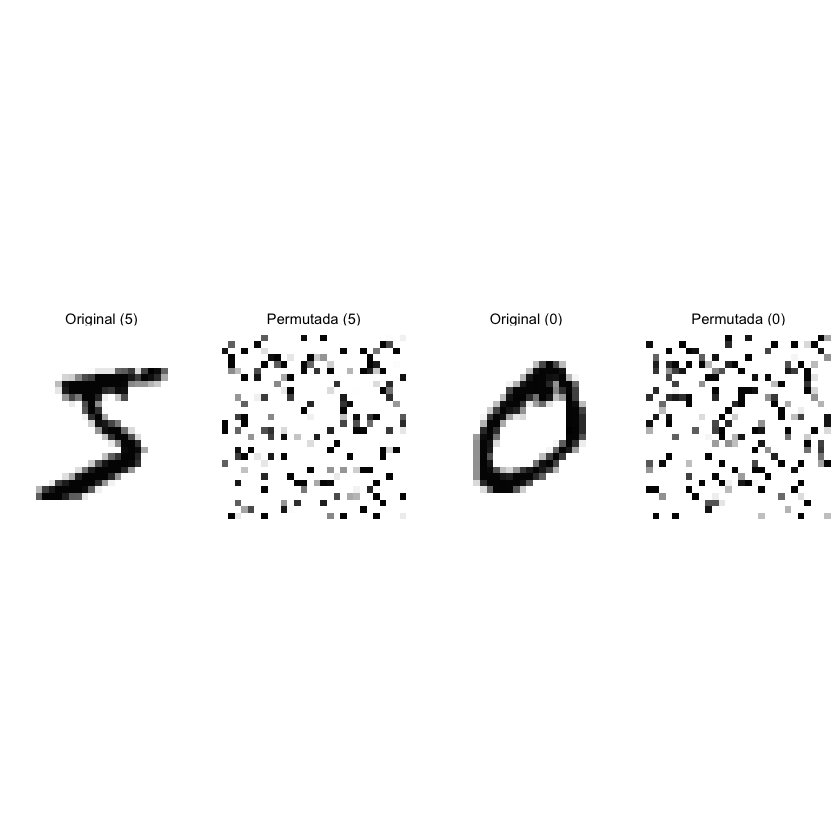

In [6]:
# array_reshape llena por filas, así que matrix(..., byrow = TRUE) recupera la imagen
graficar_digitos <- function(vectores, titulos) {
  map2_dfr(vectores, titulos, function(v, titulo) {
    m <- matrix(v, nrow = 28, byrow = TRUE)
    tibble(fila = as.vector(row(m)), columna = as.vector(col(m)),
           valor = as.vector(m), titulo = titulo)
  }) %>%
    ggplot(aes(columna, fila, fill = valor)) +
    geom_tile() +
    scale_fill_gradient(low = "white", high = "black", guide = "none") +
    scale_y_reverse() +
    facet_wrap(~ factor(titulo, levels = titulos), nrow = 1) +
    coord_equal() +
    theme_void()
}

graficar_digitos(list(x_train[1, ], x_train_perm[1, ], x_train[2, ], x_train_perm[2, ]),
                 c("Original (5)", "Permutada (5)", "Original (0)", "Permutada (0)"))

Para nosotros las imágenes permutadas parecen ruido blanco. ¿Para la red densa? 

In [7]:
construir_densa <- function() {
  red <- keras_model_sequential(input_shape = 784) %>%
    layer_dense(units = 256, activation = "relu") %>%
    layer_dropout(rate = 0.4) %>%
    layer_dense(units = 128, activation = "relu") %>%
    layer_dropout(rate = 0.3) %>%
    layer_dense(units = 10, activation = "softmax")
  red %>% compile(optimizer = "adam",
                  loss = "categorical_crossentropy",
                  metrics = "accuracy")
  red
}

entrenar_evaluar <- function(red, x_tr, x_te, epochs) {
  historia <- red %>% fit(x_tr, y_train, epochs = epochs, batch_size = 128,
                          validation_split = 0.2, verbose = 2)
  list(historia = historia,
       accuracy = evaluate(red, x_te, y_test, verbose = 0)$accuracy)
}

In [8]:
densa_original <- entrenar_evaluar(construir_densa(), x_train, x_test, epochs = 15)
densa_original$accuracy

[1] 0.9798

In [9]:
densa_permutada <- entrenar_evaluar(construir_densa(), x_train_perm, x_test_perm, epochs = 15)
densa_permutada$accuracy

[1] 0.9809

Las dos accuracies son prácticamente iguales. **La red densa no usa la informacion que un píxel esté al lado de otro.** Las CNN si

## Una red convolucional

<div >
    <img src = "figs/cnn_outline.png" />
</div>

La CNN no aplana la imagen usa la matriz $28 \times 28 \times 1$ (alto, ancho, canales; MNIST tiene un solo canal, gris).

In [10]:
x_train_img <- array_reshape(x_train, c(60000, 28, 28, 1))
x_test_img  <- array_reshape(x_test,  c(10000, 28, 28, 1))

dim(x_train_img)

[1] 60000    28    28     1

La arquitectura que vamos a usar:

- `layer_conv_2d`: 32 filtros de $3 \times 3$ que se deslizan sobre la imagen. Cada filtro calcula una suma ponderada de una vecindad de $3\times3$, con los mismos pesos en todas las posiciones.
- `layer_max_pooling_2d`: resume cada bloque de $2\times2$ con su máximo, lo que reduce la resolución a la mitad.
- Una segunda convolución con 64 filtros y otro pooling.
- `layer_flatten` y capas densas al final para clasificar, con dropout.

In [11]:
construir_cnn <- function() {
  red <- keras_model_sequential(input_shape = c(28, 28, 1)) %>%
    layer_conv_2d(filters = 32, kernel_size = c(3, 3), activation = "relu") %>%
    layer_max_pooling_2d(pool_size = c(2, 2)) %>%
    layer_conv_2d(filters = 64, kernel_size = c(3, 3), activation = "relu") %>%
    layer_max_pooling_2d(pool_size = c(2, 2)) %>%
    layer_dropout(rate = 0.25) %>%
    layer_flatten() %>%
    layer_dense(units = 128, activation = "relu") %>%
    layer_dropout(rate = 0.5) %>%
    layer_dense(units = 10, activation = "softmax")
  red %>% compile(optimizer = "adam",
                  loss = "categorical_crossentropy",
                  metrics = "accuracy")
  red
}

cnn <- construir_cnn()
summary(cnn)

Model: "sequential_2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                   │ (None, 26, 26, 32)       │           320 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 13, 13, 32)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 11, 11, 64)       │        18,496 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)    │ (None, 5, 5, 64)         │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_4 (Dropout)               │ (None, 5, 5, 64)         │             0 │
├─────

### Entrenamos

In [13]:
cnn_original <- entrenar_evaluar(cnn, x_train_img, x_test_img, epochs = 10)
cnn_original$accuracy

[1] 0.9929

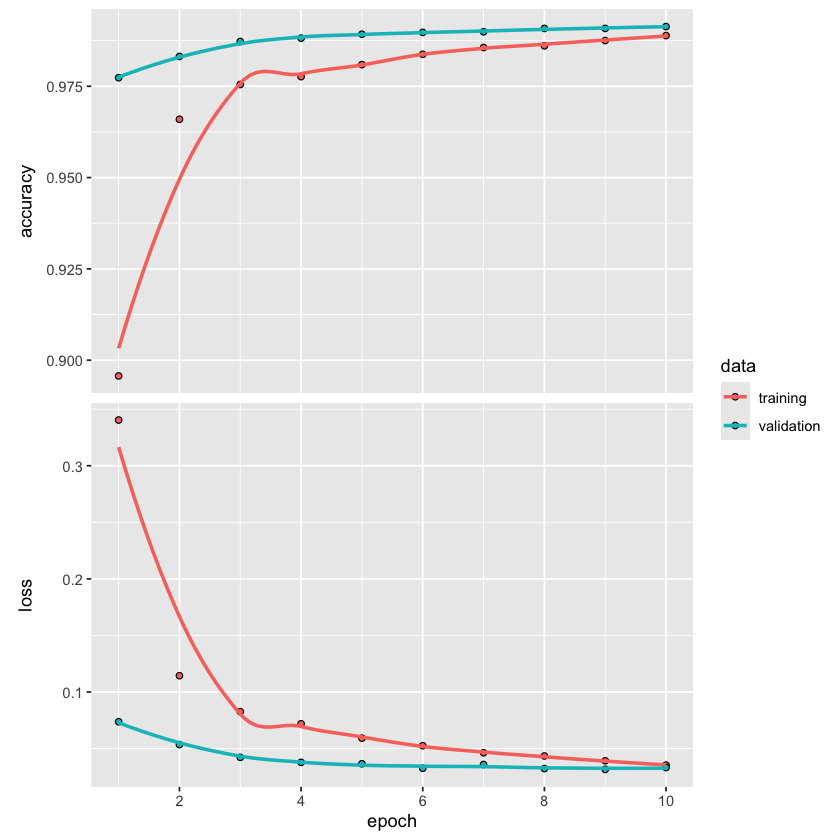

In [14]:
plot(cnn_original$historia)

## La CNN con  píxeles permutados


In [15]:
x_train_perm_img <- array_reshape(x_train_perm, c(60000, 28, 28, 1))
x_test_perm_img  <- array_reshape(x_test_perm,  c(10000, 28, 28, 1))

cnn_permutada <- entrenar_evaluar(construir_cnn(), x_train_perm_img, x_test_perm_img, epochs = 10)
cnn_permutada$accuracy

[1] 0.9681

## Takeaways

In [16]:
resultados <- tibble(
  Modelo     = c("Densa", "Densa", "CNN", "CNN"),
  Pixeles    = c("Originales", "Permutados", "Originales", "Permutados"),
  Parametros = c(rep(count_params(construir_densa()), 2), rep(count_params(cnn), 2)),
  Accuracy   = round(c(densa_original$accuracy, densa_permutada$accuracy,
                       cnn_original$accuracy, cnn_permutada$accuracy), 4)
)

resultados

Modelo,Pixeles,Parametros,Accuracy
<chr>,<chr>,<int>,<dbl>
Densa,Originales,235146,0.9798
Densa,Permutados,235146,0.9809
CNN,Originales,225034,0.9929
CNN,Permutados,225034,0.9681


## ¿Qué aprendió la CNN?

### Los filtros de la primera capa

Los pesos de la primera convolución forman un arreglo de $3 \times 3 \times 1 \times 32$: 32 filtros de $3 \times 3$. En procesamiento de imágenes estos filtros se eligen a mano (suavizar, detectar bordes); aquí los estimó backpropagation.

[1]  3  3  1 32

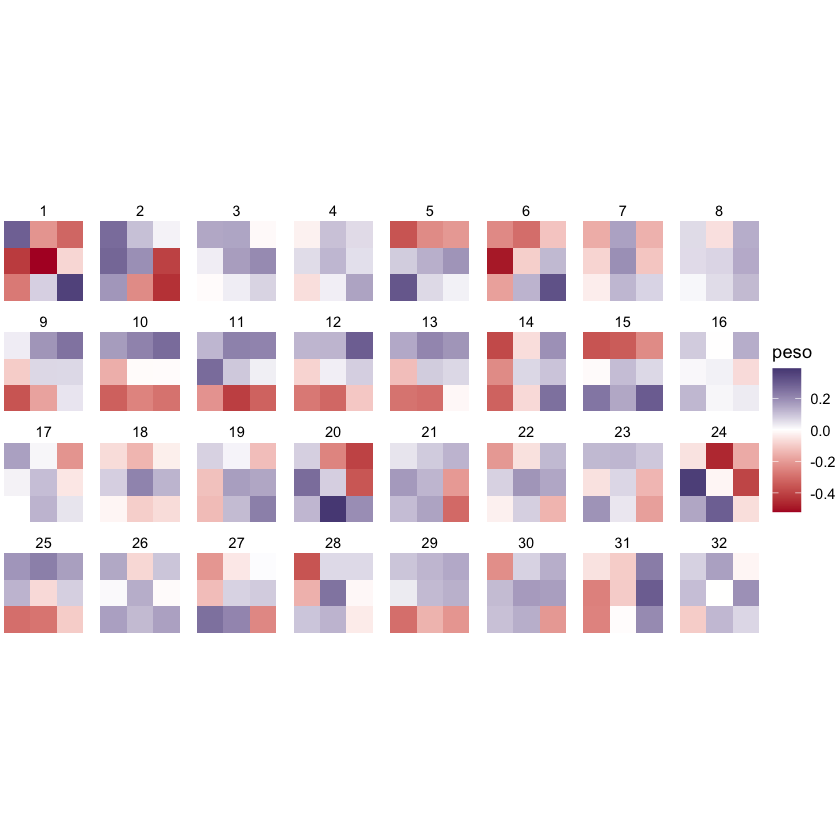

In [17]:
pesos_conv1 <- get_weights(cnn)[[1]]
dim(pesos_conv1)

filtros <- map_dfr(1:32, function(k) {
  m <- pesos_conv1[, , 1, k]
  tibble(fila = as.vector(row(m)), columna = as.vector(col(m)),
         peso = as.vector(m), filtro = k)
})

ggplot(filtros, aes(columna, fila, fill = peso)) +
  geom_tile() +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#1B175E") +
  scale_y_reverse() +
  facet_wrap(~ filtro, nrow = 4) +
  coord_equal() +
  theme_void()

### Los mapas de activación

Cada filtro produce un **canal** (*feature map*): el resultado de deslizar ese filtro sobre la imagen. Construimos un modelo que va del input a la salida de la primera convolución y lo aplicamos a un dígito del test.

[1]  1 26 26 32

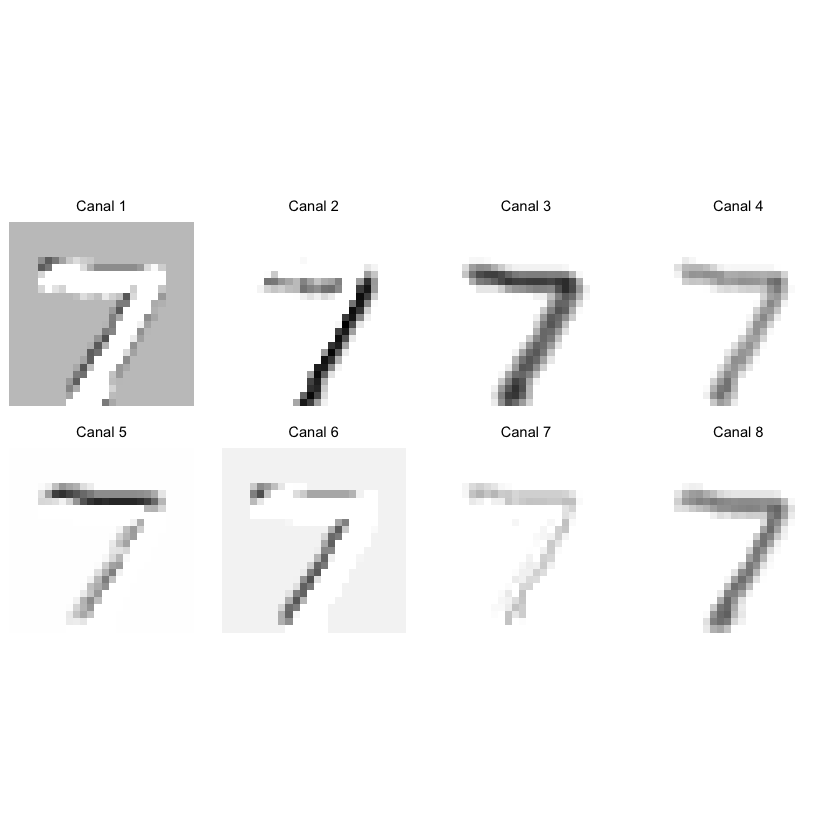

In [18]:
primera_capa <- keras_model(inputs = cnn$inputs, outputs = cnn$layers[[1]]$output)

mapas <- predict(primera_capa, x_test_img[1, , , , drop = FALSE], verbose = 0)
dim(mapas)  # 1 imagen, 26 x 26 (convolución valid), 32 canales

activaciones <- map_dfr(1:8, function(k) {
  m <- mapas[1, , , k]
  tibble(fila = as.vector(row(m)), columna = as.vector(col(m)),
         valor = as.vector(m), canal = paste("Canal", k))
})

ggplot(activaciones, aes(columna, fila, fill = valor)) +
  geom_tile() +
  scale_fill_gradient(low = "white", high = "black", guide = "none") +
  scale_y_reverse() +
  facet_wrap(~ factor(canal, levels = paste("Canal", 1:8)), nrow = 2) +
  coord_equal() +
  theme_void()

Cada canal resalta una parte distinta del mismo dígito: algunos responden a trazos horizontales, otros a verticales o a bordes de un lado. La capa siguiente combina estos canales en rasgos más complejos.
